In [1]:
from __future__ import print_function

# Standard library imports
import os
import random
import argparse

# Third-party library imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from PIL import Image
from IPython.display import HTML

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.backends.cudnn as cudnn
import torch.utils.data
import torch.nn.parallel
from torch.nn import utils

# Torchvision imports
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils

# Google Colab import
from google.colab import drive

In [2]:
#Conncect Google Drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [3]:
!unzip /content/gdrive/MyDrive/256CA.zip -d /content/CelebA-HQ-256

Streaming output truncated to the last 5000 lines.
  inflating: /content/CelebA-HQ-256/21483.jpg  
  inflating: /content/CelebA-HQ-256/19780.jpg  
  inflating: /content/CelebA-HQ-256/11086.jpg  
  inflating: /content/CelebA-HQ-256/7058.jpg  
  inflating: /content/CelebA-HQ-256/25065.jpg  
  inflating: /content/CelebA-HQ-256/15082.jpg  
  inflating: /content/CelebA-HQ-256/25768.jpg  
  inflating: /content/CelebA-HQ-256/733.jpg  
  inflating: /content/CelebA-HQ-256/9380.jpg  
  inflating: /content/CelebA-HQ-256/13755.jpg  
  inflating: /content/CelebA-HQ-256/25650.jpg  
  inflating: /content/CelebA-HQ-256/23863.jpg  
  inflating: /content/CelebA-HQ-256/2361.jpg  
  inflating: /content/CelebA-HQ-256/7592.jpg  
  inflating: /content/CelebA-HQ-256/15892.jpg  
  inflating: /content/CelebA-HQ-256/19311.jpg  
  inflating: /content/CelebA-HQ-256/21934.jpg  
  inflating: /content/CelebA-HQ-256/25317.jpg  
  inflating: /content/CelebA-HQ-256/14944.jpg  
  inflating: /content/CelebA-HQ-256/21269.j

In [4]:
!unzip /content/CelebAMask-HQ-attribute-anno.zip

Archive:  /content/CelebAMask-HQ-attribute-anno.zip
  inflating: CelebAMask-HQ-attribute-anno (2).txt  


In [5]:
df = pd.read_csv('/content/CelebAMask-HQ-attribute-anno (2).txt', sep=" ")

In [6]:
# Define constants
batch_size = 64  # Minimum value is 64
num_epochs = 10
input_dir = '/content/CelebA-HQ-256'
output_dir = '/content/'
csv_name = 'list_attr_celeba.csv'
num_workers = 2
image_size = 64
ngpu = 1
g_input_dim = 100
n_channels = 3
lr = 0.0002
beta1 = 0.5
visualization_step = 200
n_labels = 2
labels_number = [21, 9]  # 21: Male/Female, 9: Black hair/non-Black hair
load = True

# Model architecture parameters
ngf = 64  # Size of feature maps in generator
ndf = 64  # Size of feature maps in discriminator

In [7]:
class MyCustomDataset(torch.utils.data.Dataset):
# __init__ function is where the initial logic happens like reading a csv
# labels number should be an array of integers containing the number of the columns to take from the csv, like [19,13,8]
    def __init__(self, input_dir, csv_name, image_size, labels_number):

        # Create the transformation that will be applied: Resize, CenterCrop, ToTensor and Normalize
        self.transform_to_apply = transforms.Compose([
            transforms.Resize(image_size),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
          ])

        self.data_info = df

        # First column contains the image paths, second column is the labels
        self.image_arr = np.asarray(self.data_info.iloc[:, 0])

        # Create the temporary array with the labels specified, initialize it at random
        temp_labels = np.random.rand(self.image_arr.shape[0], len(labels_number))

        # For every label that we want to use we load the corresponding csv coloumn in the temporary variable
        for i in range(len(labels_number)):
            temp_labels[0:-1,i] = (self.data_info.iloc[0:-1, labels_number[i] ] )


        # Defenetively save the labels array, that will contains only the interesting labels
        self.label_arr = np.asarray(temp_labels)

        # Calculate lenght of the dataset
        self.data_len = len(self.data_info.index)

    def __getitem__(self, index):
        # __getitem__ function returns the data and labels. This function is called from dataloader
        # Get image name from the pandas df
        single_image_name = self.data_info.index[index]

        # Open image and apply the transformation
        img_as_img = Image.open(os.path.join(input_dir,single_image_name[0]))

        img = self.transform_to_apply(img_as_img)

        # Get the labels of the image based on the cropped pandas column
        single_image_label = self.label_arr[index]

        # Normalize labels between 0 and 1
        for i in range (single_image_label.size):
            if single_image_label[i] < 0:
                single_image_label[i] = 0

        return (img, single_image_label)

    def __len__(self):
        return self.data_len

In [17]:
def getDataLoader(input_dir,batch_size,image_size,num_workers,labels_number):
    # Function that will create the dataset and the dataloader and return the dataloader
    dataset = MyCustomDataset(input_dir,csv_name,image_size,labels_number)
    data_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)
    return data_loader

In [8]:
class CategoricalConditionalBatchNorm(torch.nn.Module):
    # as in the chainer SN-GAN implementation, we keep per-cat weight and bias
    def __init__(self, num_features, num_cats, eps=2e-5, momentum=0.1, affine=True,
                 track_running_stats=True):
        super().__init__()
        self.num_features = num_features
        self.num_cats = num_cats
        self.eps = eps
        self.momentum = momentum
        self.affine = affine
        self.track_running_stats = track_running_stats
        if self.affine:
            self.weight = torch.nn.Parameter(torch.Tensor(num_cats, num_features))
            self.bias = torch.nn.Parameter(torch.Tensor(num_cats, num_features))
        else:
            self.register_parameter('weight', None)
            self.register_parameter('bias', None)
        if self.track_running_stats:
            self.register_buffer('running_mean', torch.zeros(num_features))
            self.register_buffer('running_var', torch.ones(num_features))
            self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))
        else:
            self.register_parameter('running_mean', None)
            self.register_parameter('running_var', None)
            self.register_parameter('num_batches_tracked', None)
        self.reset_parameters()

    def reset_running_stats(self):
        if self.track_running_stats:
            self.running_mean.zero_()
            self.running_var.fill_(1)
            self.num_batches_tracked.zero_()

    def reset_parameters(self):
        self.reset_running_stats()
        if self.affine:
            self.weight.data.fill_(1.0)
            self.bias.data.zero_()

    def forward(self, input, cats):
        exponential_average_factor = 0.0

        if self.training and self.track_running_stats:
            self.num_batches_tracked += 1
            if self.momentum is None:  # use cumulative moving average
                exponential_average_factor = 1.0 / self.num_batches_tracked.item()
            else:  # use exponential moving average
                exponential_average_factor = self.momentum

        out = torch.nn.functional.batch_norm(
            input, self.running_mean, self.running_var, None, None,
            self.training or not self.track_running_stats,
            exponential_average_factor, self.eps)
        if self.affine:
            shape = [input.size(0), self.num_features] + (input.dim() - 2) * [1]
            weight = self.weight.index_select(0, cats).view(shape)
            bias = self.bias.index_select(0, cats).view(shape)
            out = out * weight + bias
        return out

    def extra_repr(self):
        return '{num_features}, num_cats={num_cats}, eps={eps}, momentum={momentum}, affine={affine}, ' \
               'track_running_stats={track_running_stats}'.format(**self.__dict__)

In [9]:
class Generator(nn.Module):
    # initializers
    def __init__(self, num_classes, d=128):
        super(Generator, self).__init__()
        self.deconv1_1 = nn.ConvTranspose2d(100, d*4, 4, 1, 0)
        self.deconv1_1_bn = nn.BatchNorm2d(d*4)

        self.deconv00_2 = nn.Conv2d(num_classes, int(d/4), 1, 1, 0)
        self.deconv00_2_bn = nn.BatchNorm2d(int(d/4))
        self.deconv0_2 = nn.ConvTranspose2d(int(d/4), d, 4, 1, 0)
        self.deconv0_2_bn = nn.BatchNorm2d(d)
        self.deconv1_2 = nn.ConvTranspose2d(d, d*4, 3, 1, 1)
        self.deconv1_2_bn = nn.BatchNorm2d(d*4)

        self.deconv2 = nn.ConvTranspose2d(d*8, d*4, 4, 2, 1)
        self.deconv2_bn = CategoricalConditionalBatchNorm(d*4,num_classes)
        self.deconv3 = nn.ConvTranspose2d(d*4, d*2, 4, 2, 1)
        self.deconv3_bn = CategoricalConditionalBatchNorm(d*2,num_classes)
        self.deconv4 = nn.ConvTranspose2d(d*2, d, 4, 2, 1)
        self.deconv4_bn = CategoricalConditionalBatchNorm(d,num_classes)
        self.deconv5 = nn.ConvTranspose2d(d, 3, 4, 2, 1)

    # weight_init
    def weight_init(self, mean, std):
        for m in self._modules:
            normal_init(self._modules[m], mean, std)

    # forward method
    def forward(self, input, label, cat):
        x = F.leaky_relu(self.deconv1_1_bn(self.deconv1_1(input)), 0.2)

        y = F.leaky_relu(self.deconv00_2_bn(self.deconv00_2(label)), 0.2)
        y = F.leaky_relu(self.deconv0_2_bn(self.deconv0_2(y)), 0.2)
        y = F.leaky_relu(self.deconv1_2_bn(self.deconv1_2(y)), 0.2)

        x = torch.cat([x, y], 1)
        x = F.leaky_relu(self.deconv2_bn(self.deconv2(x),cat), 0.2)
        x = F.leaky_relu(self.deconv3_bn(self.deconv3(x),cat), 0.2)
        x = F.leaky_relu(self.deconv4_bn(self.deconv4(x),cat), 0.2)
        x = torch.tanh(self.deconv5(x))

        return x

In [10]:
class Discriminator(nn.Module):
    # initializers
    def __init__(self, d=128):
        super(Discriminator, self).__init__()

        #original:
        self.conv1_1 = nn.Conv2d(3, int(d/2), 4, 2, 1)
        self.conv0_2 = nn.Conv2d(2*n_labels, int(d/4), 1, 1, 0)
        self.conv1_2 = nn.Conv2d(int(d/4), int(d/2), 4, 2, 1)

        #after union
        self.conv2 = utils.spectral_norm(nn.Conv2d(d, d*2, 4, 2, 1))
        self.conv3 = utils.spectral_norm(nn.Conv2d(d*2, d*4, 4, 2, 1))
        self.conv4 = utils.spectral_norm(nn.Conv2d(d*4, d*8, 4, 2, 1))
        self.conv5 = nn.Conv2d(d*8, 1, 4, 1, 0)

    # weight_init
    def weight_init(self, mean, std):
        for m in self._modules:
            normal_init(self._modules[m], mean, std)

    # forward method
    def forward(self, input, label):
        #original:
        x = F.leaky_relu(self.conv1_1(input), 0.2)

        y = F.leaky_relu(self.conv0_2(label), 0.2)
        y = F.leaky_relu(self.conv1_2(y), 0.2)

        x = torch.cat([x, y], 1) #Discriminator

        x = F.leaky_relu(self.conv2(x), 0.2)
        x = F.leaky_relu(self.conv3(x), 0.2)
        x = F.leaky_relu(self.conv4(x), 0.2)
        x = torch.sigmoid(self.conv5(x))

        return x

In [18]:
def normal_init(m, mean, std):
    if isinstance(m, nn.ConvTranspose2d) or isinstance(m, nn.Conv2d):
        m.weight.data.normal_(mean, std)
        m.bias.data.zero_()

In [11]:
def getDiscriminatorLabels(lbl, batch_size, image_size):
# function to get the labels as tensor for the discriminator from the real labels in a vector

    if(lbl.shape[1] == 1):

        a = torch.zeros([batch_size,2,image_size,image_size])

        for i in range(batch_size):
            if lbl[i][0] == 1:
                a[i,0,:,:] = 1
            else :
                a[i,1,:,:] = 1

        return a

    elif (lbl.shape[1] == 2):

        a = torch.zeros([batch_size,4,image_size,image_size])

        for i in range(batch_size):
          if lbl[i][0] == 1:
                a[i,0,:,:] = 1
          else :
                a[i,1,:,:] = 1
          if lbl[i][1] == 1:
                a[i,2,:,:] = 1
          else :
                a[i,3,:,:] = 1

        return a

    else:
        a = torch.zeros([batch_size,6,image_size,image_size])

        for i in range(batch_size):
          if lbl[i][0] == 1:
                a[i,0,:,:] = 1
          else :
                a[i,1,:,:] = 1
          if lbl[i][1] == 1:
                a[i,2,:,:] = 1
          else :
                a[i,3,:,:] = 1
          if lbl[i][2] == 1:
                a[i,4,:,:] = 1
          else :
                a[i,5,:,:] = 1

        return a

In [12]:
def getGeneratorLabels(lbl,batch_size):
# function to get the labels as tensor for the generator from the random labels in a vector
    if(lbl.shape[1] == 1) :

        a = torch.zeros([batch_size,2,1,1])

        for i in range(batch_size):
            if lbl[i][0] == 1:
                a[i,1,0,0] = 1
            else:
                a[i,0,0,0] = 1

        return a

    elif(lbl.shape[1] == 2):
        a = torch.zeros([batch_size,4,1,1])

        for i in range(batch_size):
            if lbl[i][0] == 1:
                a[i,1,0,0] = 1
            else:
                a[i,0,0,0] = 1
            if lbl[i][1] == 1:
                a[i,3,0,0] == 1
            else:
                a[i,2,0,0] == 1

        return a
    else:
        a = torch.zeros([batch_size,6,1,1])

        for i in range(batch_size):
            if lbl[i][0] == 1:
                a[i,1,0,0] = 1
            else:
                a[i,0,0,0] = 1
            if lbl[i][1] == 1:
                a[i,3,0,0] == 1
            else:
                a[i,2,0,0] == 1
            if lbl[i][2] == 1:
                a[i,5,0,0] = 1
            else:
                a[i,4,0,0] = 1

        return a

In [13]:
def getGeneratorCategories(lbl,batch_size):
# from the labels get the categories for the generator
    if(lbl.shape[1] == 1) :

        a = torch.zeros([batch_size])

        for i in range(batch_size):
            if lbl[i][0] == 1:
                a[i] = 1
            else:
                a[i] = 0

        b = a.long()
        return b

    elif(lbl.shape[1] == 2):
        a = torch.zeros([batch_size])

        for i in range(batch_size):
            if lbl[i][0] == 0 and lbl[i][1] == 0:
                a[i] = 0
            elif lbl[i][0] == 0 and lbl[i][1] == 1:
                a[i] = 1
            elif lbl[i][0] == 0 and lbl[i][1] == 1:
                a[i] = 2
            else:
                a[i] = 3

        b = a.long()
        return b
    else:
        a = torch.zeros([batch_size])

        for i in range(batch_size):
            if lbl[i][0] == 0 and lbl[i][1] == 0 and lbl[i][2] == 0:
                a[i] = 0
            elif lbl[i][0] == 0 and lbl[i][1] == 0 and lbl[i][2] == 1:
                a[i] = 1
            elif lbl[i][0] == 0 and lbl[i][1] == 1 and lbl[i][2] == 0:
                a[i] = 2
            elif lbl[i][0] == 0 and lbl[i][1] == 1 and lbl[i][2] == 1:
                a[i] = 3
            elif lbl[i][0] == 1 and lbl[i][1] == 0 and lbl[i][2] == 0:
                a[i] = 4
            elif lbl[i][0] == 1 and lbl[i][1] == 0 and lbl[i][2] == 1:
                a[i] = 5
            elif lbl[i][0] == 1 and lbl[i][1] == 1 and lbl[i][2] == 0:
                a[i] = 6
            else:
                a[i] = 7

        b = a.long()
        return b

In [14]:
def getGeneratorVisualizationLabels(n_features,batch_size):
    # get the generator labels in a tensor for the generator in order to have a grid of 8x8
    # generated images with alternatig labels
    remaining = batch_size - 64

    if n_features == 1:

        zeros = np.zeros((32,1))
        ones = np.ones((32,1))

        if remaining > 0:
            lbl_tmp = np.concatenate((zeros,ones),axis=0)
            remaining_zeros = np.zeros((remaining,1))
            lbl = np.concatenate((lbl_tmp,remaining_zeros),axis = 0)
        else:
            lbl = np.concatenate((zeros,ones),axis=0)

        return lbl

    elif n_features == 2:
        zeros = np.zeros((16,1))
        ones = np.ones((16,1))
        c1 = np.concatenate((zeros,ones,zeros,ones),axis =0)
        c2 = np.concatenate((zeros,zeros,ones,ones),axis =0)
        lbl = np.concatenate((c2,c1),axis=1)

        if(remaining >0):
          remaining_zeros = np.zeros((remaining,2))
          lbl = np.concatenate((lbl,remaining_zeros),axis = 0)

        return lbl

    else:
        zeros = np.zeros((8,1))
        ones = np.ones((8,1))
        c1 = np.concatenate((zeros,ones,zeros,ones,zeros,ones,zeros,ones),axis =0)
        c2 = np.concatenate((zeros,zeros,ones,ones,zeros,zeros,ones,ones),axis =0)
        c3 = np.concatenate((zeros,zeros,zeros,zeros,ones,ones,ones,ones),axis =0)
        lbl = np.concatenate((c3,c2,c1),axis=1)

        if(remaining >0):
          remaining_zeros = np.zeros((remaining,3))
          lbl = np.concatenate((lbl,remaining_zeros),axis = 0)

        return lbl

# Train the model

In [15]:
# Decide which device we want to run on
device = torch.device("cuda:0" if (torch.cuda.is_available() and ngpu > 0) else "cpu")
print("Use device: " + str(device))

Use device: cuda:0


Generator(
  (deconv1_1): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1))
  (deconv1_1_bn): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (deconv00_2): Conv2d(4, 32, kernel_size=(1, 1), stride=(1, 1))
  (deconv00_2_bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (deconv0_2): ConvTranspose2d(32, 128, kernel_size=(4, 4), stride=(1, 1))
  (deconv0_2_bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (deconv1_2): ConvTranspose2d(128, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (deconv1_2_bn): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (deconv2): ConvTranspose2d(1024, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (deconv2_bn): CategoricalConditionalBatchNorm(512, num_cats=4, eps=2e-05, momentum=0.1, affine=True, track_running_stats=True)
  (deconv3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride

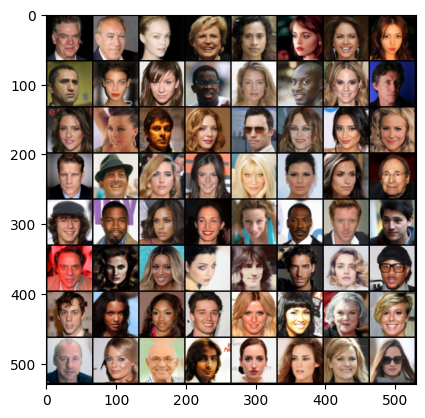

In [20]:
# tb = TensorBoardColab(graph_path='/log')
visualization_name='CELEBA-GAN-1'

# Load data
data_loader = getDataLoader(input_dir, batch_size, image_size, num_workers,labels_number)

# Save a sample of the training data
show_images = next(iter(data_loader))
plt.imshow(np.transpose(vutils.make_grid(show_images[0][0:64], padding=2, normalize=True),(1,2,0)))
plt.savefig(str(output_dir) + 'training_sample' + '.png')

# Create the Generator
netG = Generator(n_labels*2).to(device)
print(netG)

# Create the Discriminator
netD = Discriminator().to(device)
print(netD)

# Set the cost function
cost_fun = nn.BCELoss()

real_label = 1
fake_label = 0

# Create Discriminator and Generator optimizer
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

# Load the checkpoint
if load:
    checkpoint = torch.load('/content/gdrive/MyDrive/finalwalla2/epoch50_2features.pth')

    # Load the generator and discriminator state dicts
    netG.load_state_dict(checkpoint['generator'])
    netD.load_state_dict(checkpoint['discriminator'])

    # Load the optimizer state dicts
    optimizerG.load_state_dict(checkpoint['gen_optimizer'])
    optimizerD.load_state_dict(checkpoint['disc_optimizer'])
    print("Model load successfully>>>")

In [ ]:
# Start traiting
for current_epoch in range(num_epochs):

    for batch_index, (data,lbl) in enumerate(data_loader,0):
        # Encode real labels for the discriminator
        lbl_real_disc = getDiscriminatorLabels(lbl,batch_size, image_size)

        # Reset discriminator, the same as optimizerD.zero_grad()
        netD.zero_grad()
        # Train discriminator on real data
        real_data = data.to(device) #load the real data in the data variable
        lbl_real_disc = lbl_real_disc.to(device)
        # create a tensor of lenght batch size, with inside all cells the label indicating real data
        b_size = real_data.size(0)
        targets = torch.full((b_size,), real_label, device=device, dtype=torch.float32)
        # compute the output of the discriminator, that will be a number between 0 and 1 for every batch element
        outputs = netD(real_data,lbl_real_disc).view(-1)
        outputs = outputs.float()
        # Compute the loss of the discriminator
        real_loss = cost_fun(outputs,targets)
        # Backward propagation for the discriminator
        real_loss.backward()
        D_x = outputs.mean().item()

        # Get random labels (array of 1 or 0)
        fake_in_lbl_clear = np.random.randint(2, size=(batch_size,n_labels))

        # From the rangom labels get the labels for the generator
        fake_in_lbl_g = getGeneratorLabels(fake_in_lbl_clear,batch_size)
        fake_in_lbl_g = fake_in_lbl_g.to(device)

        # From the rangom labels get the labels for the discriminator
        fake_in_lbl_d = getDiscriminatorLabels(fake_in_lbl_clear,batch_size,image_size)
        fake_in_lbl_d = fake_in_lbl_d.to(device)

        fake_cat = getGeneratorCategories(fake_in_lbl_clear,batch_size)
        fake_cat = fake_cat.to(device)

        ## Train with all-fake batch
        # Generate batch of latent vectors
        noise = torch.randn(b_size, g_input_dim, 1, 1, device=device)
        # Generate fake image batch with G
        fake = netG(noise,fake_in_lbl_g,fake_cat)
        targets.fill_(fake_label)
        # Classify all fake batch with D
        output = netD(fake.detach(),fake_in_lbl_d).view(-1)
        # Calculate D's loss on the all-fake batch
        errD_fake = cost_fun(output, targets)
        # Calculate the gradients for this batch
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # Add the gradients from the all-real and all-fake batches
        errD = errD_fake
        # Update D
        optimizerD.step()

        # Train the generator
        netG.zero_grad()
        # fake labels are real for the generator, because the objective of the discriminator
        # is to generate data that seems real, so that is labeled real
        targets.fill_(real_label)
        # Reuse fake data to make the discriminator classify again
        outputs = netD(fake,fake_in_lbl_d).view(-1)
        # The loss of the generator is the difference between the output of the discriminator and the real label
        loss_g = cost_fun(outputs,targets)
        # Generator backpropagation
        loss_g.backward()
        D_G_z2 = outputs.mean().item()
        # Generator optimizer step
        optimizerG.step()

        if batch_index % visualization_step == 0:
            print('Epoch ' + str(current_epoch) + '/' + str(num_epochs) + ' batch ' + str(batch_index) + '/' + str(len(data_loader)))

            fake_vis_label_clear = getGeneratorVisualizationLabels(n_labels,batch_size)
            fake_vis_label = getGeneratorLabels(fake_vis_label_clear,batch_size)
            fake_vis_label = fake_vis_label.to(device)
            fake_vis_cat = getGeneratorCategories(fake_vis_label_clear,batch_size)
            fake_vis_cat = fake_vis_cat.to(device)

            noise_vis = torch.randn(b_size, g_input_dim, 1, 1, device=device)
            visualFake = netG(noise_vis,fake_vis_label,fake_vis_cat)
            imgplot = plt.imshow(np.transpose(vutils.make_grid(visualFake[0:64].detach().cpu(), padding=2, normalize=True),(1,2,0)))
            plt.savefig(str(output_dir) + 'result_' + str(current_epoch) + '_' + str(batch_index) + '.png')
            plt.show()

            print('Loss_D_real: ' + str(D_x) + ' Loss_D_fake: ' + str(D_G_z1) + ' Loss G: ' + str(D_G_z2) )

            current_batch = int(current_epoch*len(data_loader) + batch_index)

In [ ]:
# save the model
check_point = {
  'gen_optimizer':optimizerG.state_dict(),
  'disc_optimizer':optimizerD.state_dict(),
  'generator':netG.state_dict(),
  'discriminator':netD.state_dict()
}
torch.save(check_point, '/content/gdrive/MyDrive/finalwalla2/epoch50_2features.pth')

# Test the model

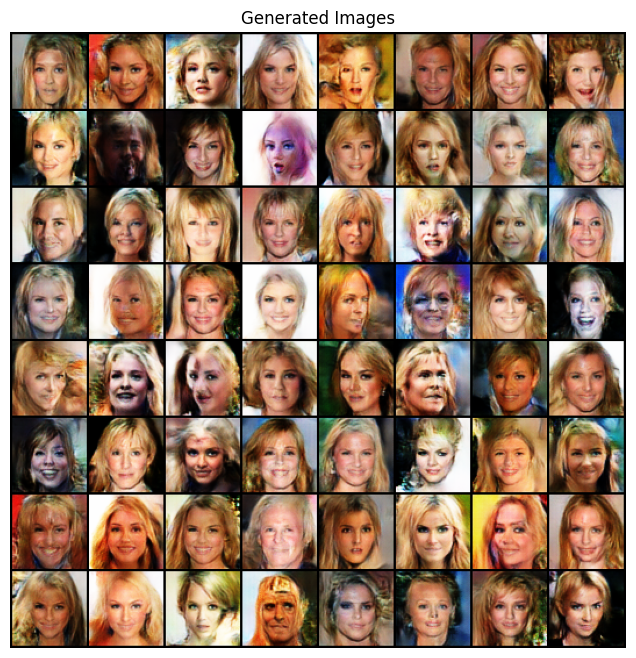

In [21]:
# Set the batch size and other parameters
batch_size = 64
g_input_dim = 100  # Adjust as per your model's input dimension
n_labels = 2  # Adjust as per your dataset's number of labels

# Prepare the input noise vector and labels
noise = torch.randn(batch_size, g_input_dim, 1, 1, device=device)

# Create random or specific labels for testing
test_labels = np.tile(np.array([0, 1]), (batch_size, 1))
# Convert labels to the required format for the generator
test_generator_labels = getGeneratorLabels(test_labels, batch_size).to(device)
test_generator_categories = getGeneratorCategories(test_labels, batch_size).to(device)

# Generate fake images
with torch.no_grad():
    fake_images = netG(noise, test_generator_labels, test_generator_categories)

# Visualize the generated images
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Generated Images")
plt.imshow(np.transpose(vutils.make_grid(fake_images.detach().cpu(), padding=2, normalize=True), (1, 2, 0)))
plt.show()
